In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

In [2]:
# Project root directory
project_dir = Path.cwd().parent

# Cleaned dataset path
cleaned_file = project_dir / "processed_data" / "retail_store_sales_cleaned.csv"

# Load dataset
df = pd.read_csv(cleaned_file)

print("Dataset loaded:", df.shape)
print("Project directory:", project_dir)

Dataset loaded: (12575, 11)
Project directory: F:\ABHISHEK\DATA SCIENCE\Mini Projects\retail-data-quality-eda


In [3]:
df["Category"].value_counts()

Category
Electric household essentials         1591
Furniture                             1591
Food                                  1588
Milk Products                         1584
Butchers                              1568
Beverages                             1567
Computers and electric accessories    1558
Patisserie                            1528
Name: count, dtype: int64

In [4]:
import matplotlib.pyplot as plt

In [5]:
category_counts = df["Category"].value_counts()

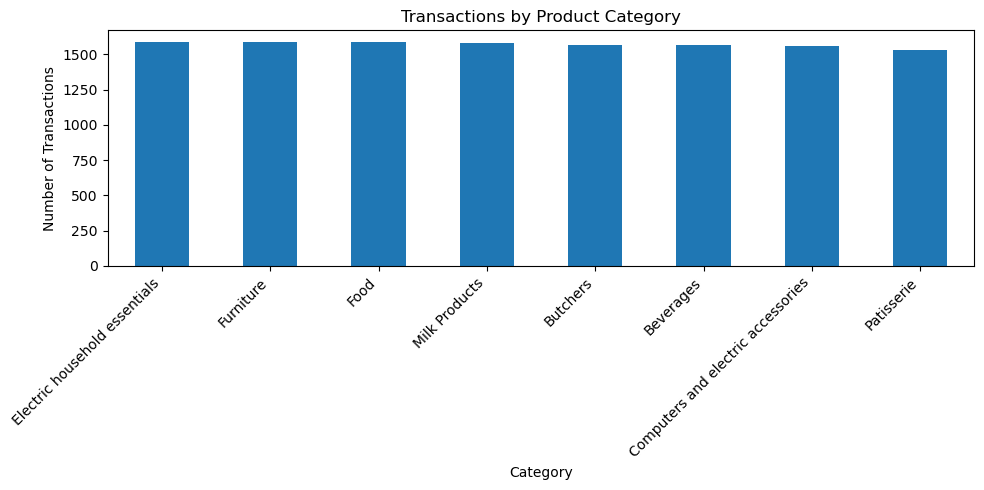

In [6]:
category_counts.plot(kind = "bar", figsize = (10, 5))

plt.title("Transactions by Product Category")
plt.xlabel("Category")
plt.ylabel("Number of Transactions")
plt.xticks(rotation = 45, ha = "right")
plt.tight_layout()
plt.show()

In [7]:
category_sales = df.groupby("Category")["Total Spent"].sum().sort_values(ascending=False)

display(category_sales)

Category
Butchers                              208118.0
Electric household essentials         203813.5
Beverages                             197047.5
Furniture                             195310.0
Food                                  194812.0
Computers and electric accessories    190692.5
Patisserie                            182165.5
Milk Products                         180112.0
Name: Total Spent, dtype: float64

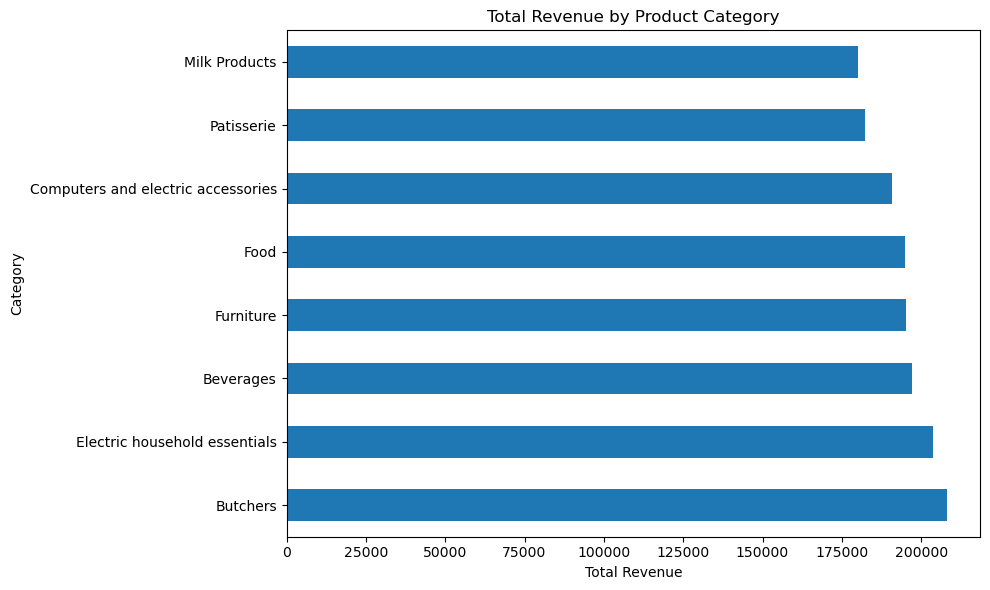

In [8]:
category_sales.plot(kind="barh", figsize=(10, 6))

plt.title("Total Revenue by Product Category")
plt.xlabel("Total Revenue")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [9]:
category_avg = df.groupby("Category")["Total Spent"].mean().sort_values(ascending=False)

display(category_avg)

Category
Butchers                              139.116310
Electric household essentials         134.441623
Beverages                             131.716243
Food                                  129.271400
Computers and electric accessories    129.107989
Furniture                             128.072131
Patisserie                            126.416031
Milk Products                         119.042961
Name: Total Spent, dtype: float64

In [10]:
payment_counts = df["Payment Method"].value_counts()

display(payment_counts)

Payment Method
Cash              4310
Digital Wallet    4144
Credit Card       4121
Name: count, dtype: int64

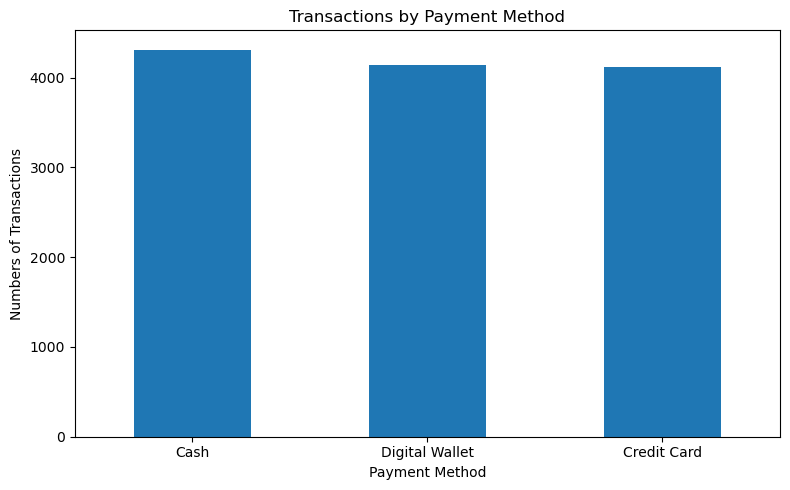

In [11]:
payment_counts.plot(kind = "bar", figsize = (8,5))

plt.title("Transactions by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Numbers of Transactions")
plt.xticks(rotation = 0)

plt.tight_layout()
plt.show()

In [12]:
payment_revenue = (
    df.groupby("Payment Method")["Total Spent"].sum().sort_values(ascending=False)
)

display(payment_revenue)

Payment Method
Cash              537710.0
Digital Wallet    507279.0
Credit Card       507082.0
Name: Total Spent, dtype: float64

In [13]:
payment_avg = (
    df.groupby("Payment Method")["Total Spent"]
    .mean()
    .sort_values(ascending=False)
)

display(payment_avg)

Payment Method
Cash              131.052888
Credit Card       129.127069
Digital Wallet    128.718346
Name: Total Spent, dtype: float64

In [14]:
location_counts = df["Location"].value_counts()

display(location_counts)

Location
Online      6354
In-store    6221
Name: count, dtype: int64

In [15]:
location_revenue = (
    df.groupby("Location")["Total Spent"]
    .sum()
    .sort_values(ascending=False)
)

display(location_revenue)

Location
Online      791401.0
In-store    760670.0
Name: Total Spent, dtype: float64

In [16]:
location_avg = (
    df.groupby("Location")["Total Spent"]
    .mean()
    .sort_values(ascending=False)
)

display(location_avg)

Location
Online      130.422050
In-store    128.861596
Name: Total Spent, dtype: float64

In [17]:
df["Transaction Date"] = pd.to_datetime(df["Transaction Date"])

df["Transaction Date"].dtype

dtype('<M8[ns]')

In [18]:
monthly_sales = (
    df.groupby(df["Transaction Date"].dt.to_period("M"))["Total Spent"]
    .sum()
)

display(monthly_sales)

Transaction Date
2022-01    52911.5
2022-02    43325.5
2022-03    40996.0
2022-04    40442.0
2022-05    40347.5
2022-06    42576.0
2022-07    44471.5
2022-08    41333.5
2022-09    46113.5
2022-10    38355.0
2022-11    41256.5
2022-12    38201.0
2023-01    48052.5
2023-02    39214.5
2023-03    38534.5
2023-04    38905.5
2023-05    40480.5
2023-06    42474.0
2023-07    45632.5
2023-08    38592.0
2023-09    41069.0
2023-10    38322.0
2023-11    37014.0
2023-12    43021.0
2024-01    47908.5
2024-02    37145.0
2024-03    42861.5
2024-04    46271.0
2024-05    43766.5
2024-06    44721.0
2024-07    41405.0
2024-08    43362.0
2024-09    42161.5
2024-10    42736.5
2024-11    44076.0
2024-12    48466.5
2025-01    25548.5
Freq: M, Name: Total Spent, dtype: float64

In [19]:
highest_month = monthly_sales.idxmax()
lowest_month = monthly_sales.idxmin()

print("Highest Revenue Month:", highest_month)
print("Highest Revenue:", monthly_sales.max())

print("\nLowest Revenue Month:", lowest_month)
print("Lowest Revenue:", monthly_sales.min())

Highest Revenue Month: 2022-01
Highest Revenue: 52911.5

Lowest Revenue Month: 2025-01
Lowest Revenue: 25548.5


In [20]:
print("First Transaction:", df["Transaction Date"].min())
print("Last Transaction:", df["Transaction Date"].max())

First Transaction: 2022-01-01 00:00:00
Last Transaction: 2025-01-18 00:00:00


In [21]:
monthly_sales_complete = monthly_sales[
    monthly_sales.index != "2025-01"
]

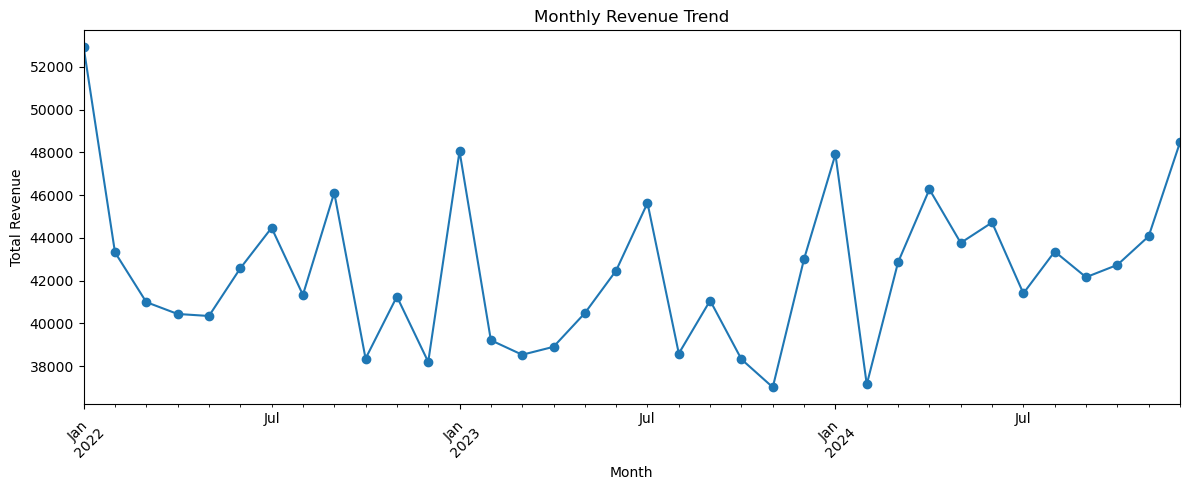

In [22]:
monthly_sales_complete.plot(
    kind="line",
    figsize=(12, 5),
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [23]:
yearly_revenue = (
    df.groupby(df["Transaction Date"].dt.year)["Total Spent"]
    .sum()
)

display(yearly_revenue)

Transaction Date
2022    510329.5
2023    491312.0
2024    524881.0
2025     25548.5
Name: Total Spent, dtype: float64

In [24]:
top_products = (
    df.groupby("Item")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_products)

Item
Unavailable     3387.0
Item_2_BEV       676.0
Item_16_MILK     627.0
Item_25_FUR      616.0
Item_19_MILK     589.0
Item_13_FOOD     581.0
Item_5_FUR       581.0
Item_1_MILK      578.0
Item_11_MILK     574.0
Item_11_FUR      573.0
Name: Quantity, dtype: float64

In [25]:
top_products = (
    df[df["Item"] != "Unavailable"]
    .groupby("Item")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_products)

Item
Item_2_BEV      676.0
Item_16_MILK    627.0
Item_25_FUR     616.0
Item_19_MILK    589.0
Item_5_FUR      581.0
Item_13_FOOD    581.0
Item_1_MILK     578.0
Item_11_MILK    574.0
Item_11_FUR     573.0
Item_14_FOOD    566.0
Name: Quantity, dtype: float64

In [26]:
category_demand = (
    df.groupby("Category")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

display(category_demand)

Category
Furniture                             8462.0
Food                                  8387.0
Beverages                             8358.0
Milk Products                         8339.0
Electric household essentials         8309.0
Computers and electric accessories    8272.0
Butchers                              8206.0
Patisserie                            7943.0
Name: Quantity, dtype: float64

In [27]:
category_comparison = df.groupby("Category").agg(
    Total_Quantity=("Quantity", "sum"),
    Total_Revenue=("Total Spent", "sum")
)

display(category_comparison)

,Total_Quantity,Total_Revenue
Category,,
Beverages,8358.0,197047.5
Butchers,8206.0,208118.0
Computers and electric accessories,8272.0,190692.5
Electric household essentials,8309.0,203813.5
Food,8387.0,194812.0
Furniture,8462.0,195310.0
Milk Products,8339.0,180112.0
Patisserie,7943.0,182165.5


In [28]:
customer_orders = df["Customer ID"].value_counts()

repeat_customers = customer_orders[customer_orders > 1]

print("Total Customers:", df["Customer ID"].nunique())
print("Repeat Customers:", len(repeat_customers))
print("One-time Customers:", (customer_orders == 1).sum())

Total Customers: 25
Repeat Customers: 25
One-time Customers: 0


In [29]:
customer_revenue = (
    df.groupby("Customer ID")["Total Spent"]
    .sum()
    .sort_values(ascending=False)
)

display(customer_revenue.head(10))

Customer ID
CUST_24    68452.0
CUST_08    67351.5
CUST_05    66974.5
CUST_16    65570.5
CUST_13    65037.0
CUST_23    64507.0
CUST_10    63155.5
CUST_15    63117.5
CUST_21    62933.0
CUST_02    62046.5
Name: Total Spent, dtype: float64

In [30]:
top_10_revenue = customer_revenue.head(10).sum()

total_revenue = df["Total Spent"].sum()

contribution = (top_10_revenue / total_revenue) * 100

print("Top 10 Revenue Contribution:", round(contribution, 2), "%")

Top 10 Revenue Contribution: 41.82 %


In [33]:
correlation = df[
    ["Price Per Unit", "Quantity", "Total Spent"]
].corr()

display(correlation)

,Price Per Unit,Quantity,Total Spent
Price Per Unit,1.000000,0.010357,0.630616
Quantity,0.010357,1.000000,0.712069
Total Spent,0.630616,0.712069,1.000000


### Correlation Analysis – Interpretation

- Price Per Unit and Quantity show almost no linear correlation.
- Quantity and Total Spent show a positive correlation.
- Price Per Unit and Total Spent also show a positive correlation.

**Limitation:** Total Spent is mathematically related to Price Per Unit and Quantity in this dataset. Therefore, these correlations should not be interpreted as independent business discoveries or evidence of causation.